# ChurnGuard: EDA

All conclusions below use the **training split only** (70%). Validation and test splits are not loaded in this notebook (CLAUDE.md rule 1).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from churnguard.data.split import load_split

plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
train = load_split('train')
train['tenure_bucket'] = pd.cut(
    train['tenure'], [-1, 12, 24, 48, 100], labels=['0-12', '13-24', '25-48', '49+']
)
print(train.shape)
train.head()

(4930, 22)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_bucket
0,6918-UMQCG,Female,0,No,No,5,Yes,No,Fiber optic,No,...,No,Yes,No,Month-to-month,No,Electronic check,80.20,384.25,0,0-12
1,4140-MUHUG,Female,1,No,No,3,Yes,No,Fiber optic,No,...,No,Yes,No,Month-to-month,Yes,Electronic check,86.85,220.95,1,0-12
2,5570-PTWEH,Female,0,Yes,No,3,Yes,Yes,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Credit card (automatic),75.15,216.75,1,0-12
3,2054-PJOCK,Female,0,No,No,60,Yes,Yes,DSL,No,...,Yes,Yes,Yes,One year,No,Credit card (automatic),80.55,4847.05,0,49+
4,4315-MURBD,Female,0,No,No,12,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),98.90,1120.95,1,0-12


## Cleaning issues handled before this point
- `TotalCharges` had 11 blank strings in the raw file, all with `tenure == 0`; coerced to numeric and filled with 0.
- `No internet service` / `No phone service` folded into `No`; `InternetService` and `PhoneService` keep the parent information.
- `Churn` encoded as 1/0. No other nulls; `customerID` is unique.

## Churn rate

Churn rate (train): 26.5%  (1308 of 4930)


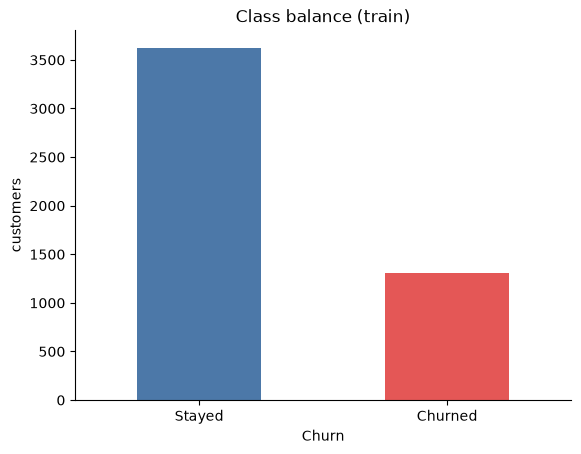

In [2]:
rate = train['Churn'].mean()
print(f'Churn rate (train): {rate:.1%}  ({train.Churn.sum()} of {len(train)})')
train['Churn'].map({0: 'Stayed', 1: 'Churned'}).value_counts().plot.bar(color=['#4c78a8', '#e45756'], rot=0)
plt.ylabel('customers'); plt.title('Class balance (train)'); plt.show()

## Churn rate by segment

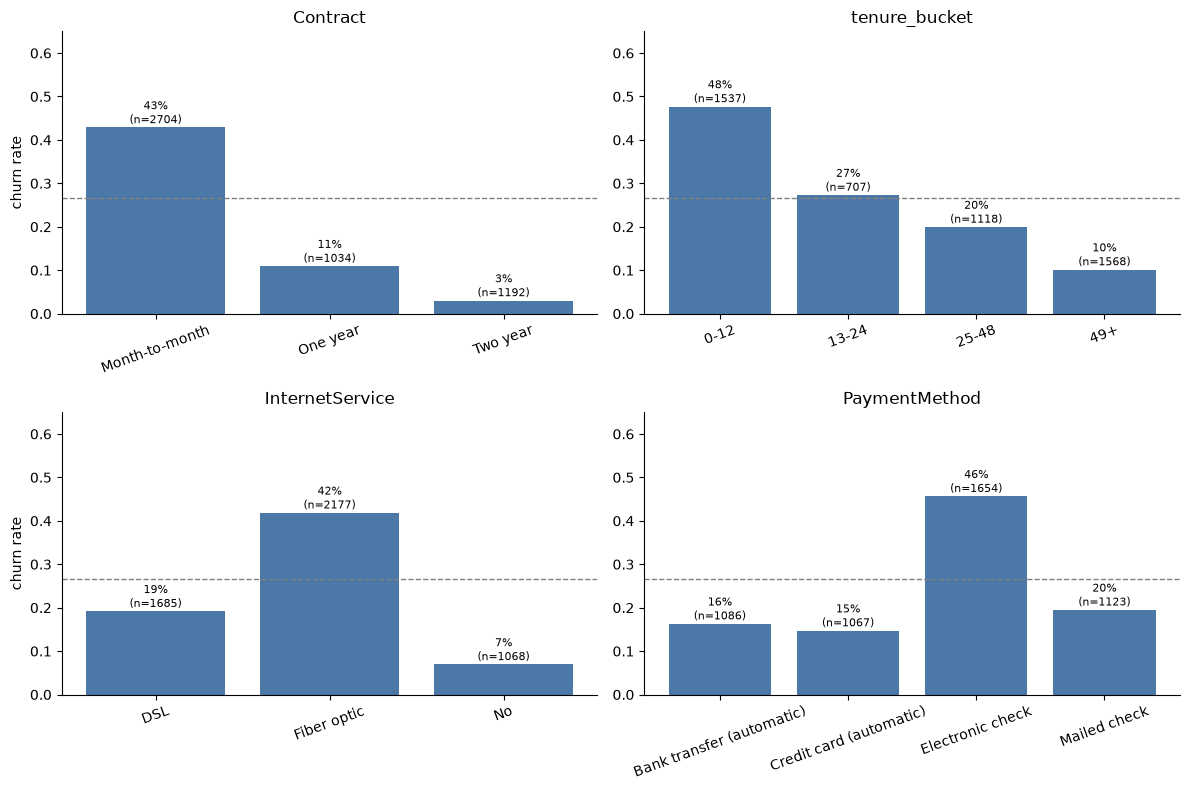

In [3]:
def churn_by(col, ax):
    g = train.groupby(col, observed=True)['Churn'].agg(['mean', 'size'])
    ax.bar(g.index.astype(str), g['mean'], color='#4c78a8')
    ax.axhline(rate, color='grey', ls='--', lw=1)
    for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
        ax.text(i, m + 0.01, f'{m:.0%}\n(n={n})', ha='center', fontsize=8)
    ax.set_title(col); ax.set_ylim(0, 0.65); ax.tick_params(axis='x', labelrotation=20)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, ax in zip(['Contract', 'tenure_bucket', 'InternetService', 'PaymentMethod'], axes.ravel()):
    churn_by(col, ax)
axes[0, 0].set_ylabel('churn rate'); axes[1, 0].set_ylabel('churn rate')
plt.tight_layout(); plt.show()

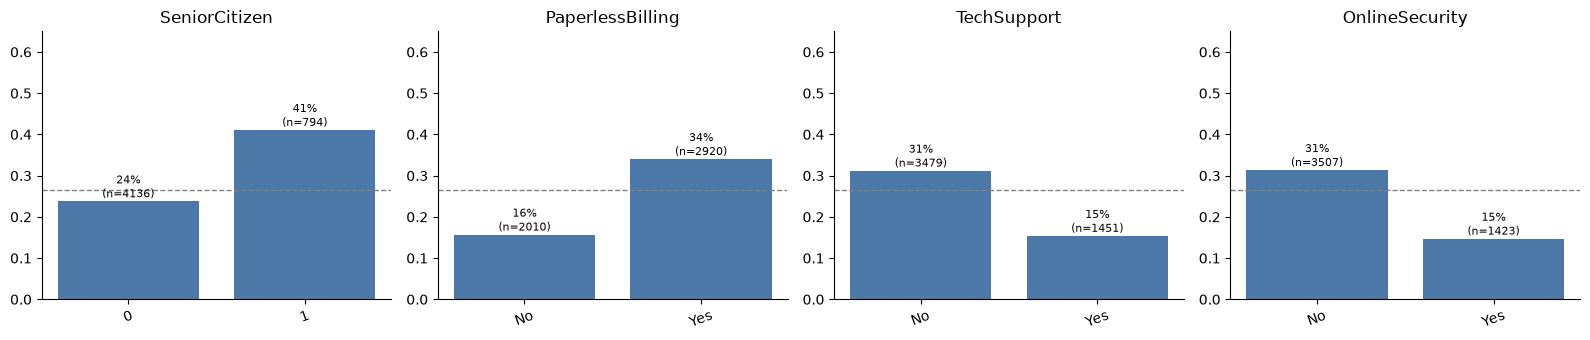

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for col, ax in zip(['SeniorCitizen', 'PaperlessBilling', 'TechSupport', 'OnlineSecurity'], axes):
    churn_by(col, ax)
plt.tight_layout(); plt.show()

## Numeric distributions

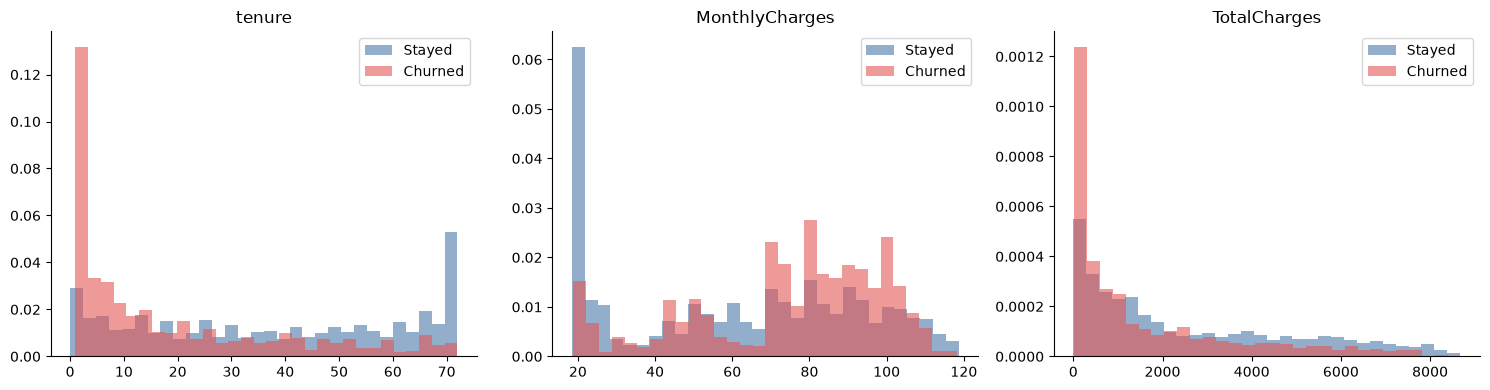

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,38.0,64.45,1673.600
1,10.0,80.00,705.075


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax in zip(['tenure', 'MonthlyCharges', 'TotalCharges'], axes):
    for label, color, name in [(0, '#4c78a8', 'Stayed'), (1, '#e45756', 'Churned')]:
        ax.hist(train.loc[train.Churn == label, col], bins=30, alpha=0.6, color=color, label=name, density=True)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()
train.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].median()

## Correlations

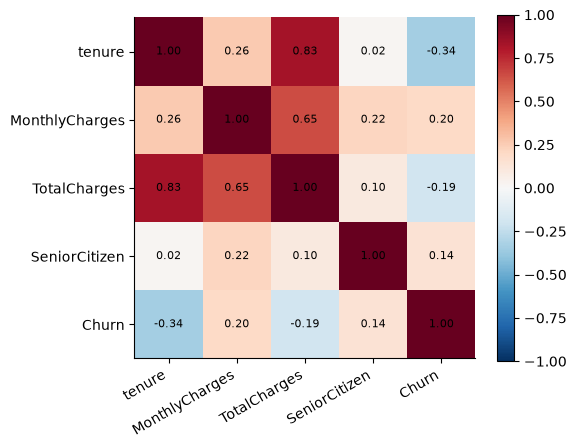

tenure           -0.344
MonthlyCharges    0.200
TotalCharges     -0.190
SeniorCitizen     0.144
Name: Churn, dtype: float64

In [6]:
num = train[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn']]
corr = num.corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=30, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im); plt.show()
corr['Churn'].drop('Churn').round(3)

## Findings (train split)

1. **Churn rate is 26.5%** (about 73/27), so stratified splits and PR-AUC as the primary metric are justified.
2. **Contract type is the strongest segment signal:** month-to-month churns at 43%, one-year at 11%, two-year at 3%.
3. **Tenure matters a lot:** customers in their first 12 months churn at 48%, falling to 10% after 49 months. Median tenure is 10 months for churners vs 38 for stayers; tenure has the strongest numeric correlation with churn (-0.34).
4. **Fiber optic customers churn at 42%** vs 19% for DSL and 7% for no internet. Monthly charges are higher for churners (median 80 vs 64), which is partly the fiber effect; we cannot separate price from product with this data.
5. **Electronic-check payers churn at 46%**; the three other methods are 15-20%. Automatic payment looks protective, but it is also correlated with contract length, so this is an association, not a causal claim.
6. **Add-on support services go with lower churn:** with tech support 15% vs 31% without; same pattern for online security.
7. **Seniors churn at 41%** vs 24% for non-seniors; paperless billing 34% vs 16%. Seniors are 16% of customers, so this is a slice to monitor for fairness (Block 4).
8. `TotalCharges` is largely `tenure x MonthlyCharges`, so it is redundant with those two; the engineered `avg_monthly_spend` and `charge_delta` features in Block 2 will test whether it adds anything.

These are descriptive associations from one telecom dataset, not causal effects.